# 04 KG-guided recognition: training and evaluation

**Model.** Image side: frozen MONET features plus a zero-initialised residual adapter. Class side: an R-GCN runs over the knowledge graph and generates a classifier weight for every disease, added to the disease's MONET text embedding through a zero-initialised projection. At initialisation the model is exactly MONET zero-shot with KG text prompts; training only learns what the graph adds. Unseen diseases have nodes and edges in the graph, so they receive classifier weights without any training images.

**Settings**

| Setting | Train | Test | Repeats |
|---|---|---|---|
| ZSL / GZSL | images of seen diseases | unseen diseases (ZSL); seen + unseen (GZSL) | `N_SPLITS` different unseen sets |
| Long-tail | all diseases, closed-set split | closed-set test, head / medium / tail | `LT_SEEDS` |
| Ablation | as ZSL, one relation group removed | unseen diseases | `N_SPLITS` |

Runs are appended to `results_v2/runs.jsonl`; re-running skips finished runs, so the notebook can be stopped and resumed. Every figure is its own cell and its own file in `figures_v2/` (PDF + PNG). LaTeX tables go to `results_v2/tables.tex`.

`pip install torch numpy pandas scikit-learn matplotlib pillow tqdm`

In [1]:
# ============ Config ============
from pathlib import Path

DATA = Path('data_v2'); FEAT = DATA / 'features'; KG = DATA / 'kg'
RES  = Path('results_v2'); FIG = Path('figures_v2')

BACKBONE   = 'monet'        # image features
TEXT_SRC   = 'monet'        # text features for disease nodes (needs a text encoder)
TEXT_VIEW  = 'full_text'    # name_text | attr_text | full_text
OURS       = 'Ours'         # display name of the proposed model

# model
HID, LAYERS, BASES, DROPOUT = 256, 2, 8, 0.1
LOGIT_SCALE = 30.0
# training
EPOCHS, BATCH, LR, WD, PATIENCE = 40, 512, 1e-3, 1e-4, 8
# protocol
N_SPLITS    = 5             # ZSL: number of unseen-class splits (split 0 = the one from 01)
UNSEEN_FRAC = 0.20
LT_SEEDS    = [0, 1, 2]
ZSL_METHODS = ['zs_name', 'zs_full', 'attr', 'text', 'kg', 'kg_notext', 'kg_rand']
LT_METHODS  = ['zs_full', 'lp', 'lp_la', 'text', 'kg', 'kg_la']
ABLATION    = True          # leave-one-relation-group-out on the ZSL splits
N_CASES     = 3             # case-study figures

QUICK = False               # True: 2 splits, 1 seed, 10 epochs, for a fast end-to-end check
FORCE = False               # True: ignore finished runs and retrain everything
if QUICK:
    N_SPLITS, LT_SEEDS, EPOCHS = 2, [0], 10
    RES = Path('results_v2_quick')

for d in (RES, RES / 'models', RES / 'preds', FIG):
    d.mkdir(parents=True, exist_ok=True)

In [3]:
import json, math, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(max(1, torch.get_num_threads()))

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight', 'savefig.dpi': 300})
PAL = {'zs_name': '#bdbdbd', 'zs_full': '#8c8c8c', 'attr': '#a6cee3', 'text': '#1f78b4',
       'kg': '#c1121f', 'kg_notext': '#f4a261', 'kg_rand': '#e9c46a',
       'lp': '#b2df8a', 'lp_la': '#33a02c', 'kg_la': '#7f0000'}
NAMES = {'zs_name': 'MONET zero-shot (name)', 'zs_full': 'MONET zero-shot (KG text)',
         'attr': 'Attribute MLP', 'text': 'Text projection', 'kg': OURS,
         'kg_notext': f'{OURS} w/o text init', 'kg_rand': f'{OURS}, shuffled graph',
         'lp': 'Linear probe', 'lp_la': 'Linear probe + LA', 'kg_la': f'{OURS} + LA'}

def savefig(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG / f'{name}.{ext}')
    print('saved', FIG / f'{name}.pdf')
print('device:', DEVICE)

device: cuda


c:\Users\78479\anaconda3\envs\skin311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

In [4]:
meta = pd.read_csv(DATA / 'meta.csv')
tax  = pd.read_csv(DATA / 'taxonomy.csv').sort_values('disease_id').reset_index(drop=True)
Cn   = len(tax)
y    = meta['disease_id'].to_numpy()

X = np.load(FEAT / BACKBONE / 'image.npy').astype(np.float32)
T = np.load(FEAT / TEXT_SRC / f'text_{TEXT_VIEW}.npy').astype(np.float32)
T_name = np.load(FEAT / TEXT_SRC / 'text_name_text.npy').astype(np.float32)
Xt, Tt = torch.from_numpy(X).to(DEVICE), torch.from_numpy(T).to(DEVICE)
D, Dt = X.shape[1], T.shape[1]
SAME_SPACE = (BACKBONE == TEXT_SRC)          # zero-shot baselines need a shared image-text space
if not SAME_SPACE:
    ZSL_METHODS = [m for m in ZSL_METHODS if not m.startswith('zs_')]
    LT_METHODS  = [m for m in LT_METHODS if not m.startswith('zs_')]

attr_df = pd.read_csv(KG / 'disease_attributes.csv').sort_values('disease_id')
A_attr  = torch.tensor(attr_df.drop(columns=['disease_id', 'disease']).to_numpy(), dtype=torch.float32, device=DEVICE)

cat_of   = tax['category'].to_numpy()
img_path = meta['cache_path'].where(meta['cache_path'].notna(), meta['path']).to_numpy()
print(f'{len(meta)} images | {Cn} diseases | image dim {D} | text dim {Dt} | attributes {A_attr.shape[1]}')

16321 images | 114 diseases | image dim 768 | text dim 768 | attributes 118


## 2. Knowledge graph as relation-specific adjacency

In [5]:
nodes = pd.read_csv(KG / 'nodes.csv')
edges = pd.read_csv(KG / 'edges.csv')

# global node order: diseases first (row = disease_id), then all other nodes
NODE = ['Disease:' + d for d in tax['disease']] + [n for n in nodes['node_id'] if not n.startswith('Disease:')]
NID  = {n: i for i, n in enumerate(NODE)}
NN, N_OTHER = len(NODE), len(NODE) - Cn
edges = edges[edges['head'].isin(NID) & edges['tail'].isin(NID)].reset_index(drop=True)

GROUPS = {'morphology': ['HAS_MORPHOLOGY'], 'secondary change': ['HAS_SECONDARY'], 'color': ['HAS_COLOR'],
          'configuration': ['HAS_CONFIGURATION'], 'location': ['LOCATED_AT'], 'etiology': ['HAS_ETIOLOGY'],
          'symptom': ['HAS_SYMPTOM'], 'taxonomy': ['BELONGS_TO', 'IS_A'],
          'disease-disease': ['SUBTYPE_OF', 'DIFFERENTIAL_OF', 'SIMILAR_TO']}
ATTR_RELS = ['HAS_MORPHOLOGY', 'HAS_SECONDARY', 'HAS_COLOR', 'HAS_CONFIGURATION',
             'LOCATED_AT', 'HAS_ETIOLOGY', 'HAS_SYMPTOM']
SYMMETRIC = {'DIFFERENTIAL_OF'}
ALL_RELS  = sorted(edges['relation'].unique())
REL_SLOTS = [r for rel in ALL_RELS for r in ([rel] if rel in SYMMETRIC else [rel, rel + '_inv'])]

def build_adj(e):
    # one row-normalised adjacency per relation direction; row i aggregates messages for node i.
    # the slot list is fixed so ablated graphs keep the same parameter shapes (removed slots are empty)
    A = torch.zeros(len(REL_SLOTS), NN, NN)
    for k, slot in enumerate(REL_SLOTS):
        rel, inv = (slot[:-4], True) if slot.endswith('_inv') else (slot, False)
        g = e[e['relation'] == rel]
        if g.empty:
            continue
        h = torch.tensor(g['head'].map(NID).to_numpy()); t = torch.tensor(g['tail'].map(NID).to_numpy())
        w = torch.tensor(g['weight'].to_numpy(), dtype=torch.float32)
        dst, src = (t, h) if inv else (h, t)
        A[k].index_put_((dst, src), w, accumulate=True)
    deg = A.sum(2, keepdim=True)
    return (A / torch.where(deg > 0, deg, torch.ones_like(deg))).to(DEVICE)

def shuffled_edges(e, seed):
    # type-preserving rewiring: permute tails within each relation (keeps degrees and node types)
    rng = np.random.default_rng(seed); out = e.copy()
    for _, g in out.groupby('relation'):
        out.loc[g.index, 'tail'] = rng.permutation(g['tail'].to_numpy())
    return out

def drop_group(e, group):
    return e[~e['relation'].isin(GROUPS[group])]

ADJ = build_adj(edges)
print(f'{NN} nodes ({Cn} diseases, {N_OTHER} others) | {len(edges)} edges | {len(REL_SLOTS)} relation slots')

244 nodes (114 diseases, 130 others) | 2412 edges | 25 relation slots


## 3. Model

In [6]:
class RGCNLayer(nn.Module):
    def __init__(self, R, d, B, p):
        super().__init__()
        self.bases = nn.Parameter(torch.randn(B, d, d) / d ** 0.5)
        self.comp = nn.Parameter(torch.randn(R, B) / B ** 0.5)
        self.self_lin = nn.Linear(d, d)
        self.norm, self.drop = nn.LayerNorm(d), nn.Dropout(p)
    def forward(self, h, A):
        W = torch.einsum('rb,bij->rij', self.comp, self.bases)          # basis decomposition
        m = torch.einsum('rnm,md->rnd', A, h)                            # mean over neighbours, per relation
        out = torch.einsum('rnd,rde->ne', m, W) + self.self_lin(h)
        return self.norm(h + self.drop(F.gelu(out)))

def zero_linear(i, o):
    l = nn.Linear(i, o); nn.init.zeros_(l.weight); nn.init.zeros_(l.bias); return l

class Net(nn.Module):
    # kind: free (linear probe) | text | attr | kg | kg_notext
    def __init__(self, kind, adj=None):
        super().__init__()
        self.kind = kind
        self.adapter = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(D, D), nn.GELU(), zero_linear(D, D))
        self.log_scale = nn.Parameter(torch.tensor(math.log(LOGIT_SCALE)))
        if kind == 'free':
            self.W = nn.Parameter(torch.randn(Cn, D) * 0.02)
        if kind in ('text', 'kg'):
            # residual on the text embedding; identity at init when image and text share a space
            self.t_res = zero_linear(Dt, D) if Dt == D and SAME_SPACE else nn.Linear(Dt, D)
        if kind == 'attr':
            self.a_mlp = nn.Sequential(nn.Linear(A_attr.shape[1], HID), nn.GELU(), nn.Linear(HID, D))
        if kind.startswith('kg'):
            self.register_buffer('adj', adj)
            self.other = nn.Embedding(N_OTHER, HID)
            self.dis_in = nn.Linear(Dt, HID) if kind == 'kg' else None
            self.dis_tok = nn.Parameter(torch.zeros(HID)) if kind == 'kg_notext' else None
            self.gnn = nn.ModuleList(RGCNLayer(len(REL_SLOTS), HID, BASES, DROPOUT) for _ in range(LAYERS))
            self.g_out = zero_linear(HID, D) if kind == 'kg' else nn.Linear(HID, D)

    def node_states(self, adj=None):
        hd = self.dis_in(Tt) if self.kind == 'kg' else self.dis_tok.expand(Cn, -1)
        h = torch.cat([hd, self.other.weight])
        for layer in self.gnn:
            h = layer(h, self.adj if adj is None else adj)
        return h

    def class_weights(self, adj=None):
        if self.kind == 'free':
            return self.W
        if self.kind == 'attr':
            return self.a_mlp(A_attr)
        w = 0
        if self.kind in ('text', 'kg'):
            w = (Tt + self.t_res(Tt)) if (Dt == D and SAME_SPACE) else self.t_res(Tt)
        if self.kind.startswith('kg'):
            w = w + self.g_out(self.node_states(adj)[:Cn])
        return w

    def image_features(self, x):
        return x + self.adapter(x)

    def forward(self, x, adj=None):
        f = F.normalize(self.image_features(x), dim=-1)
        W = F.normalize(self.class_weights(adj), dim=-1)
        return self.log_scale.exp().clamp(max=100) * f @ W.T

print('parameters (kg):', sum(p.numel() for p in Net('kg', ADJ).parameters()))

parameters (kg): 3380881


## 4. Training and metrics

In [7]:
def bacc(pred, yt):
    return float(np.mean([(pred[yt == c] == c).mean() for c in np.unique(yt)]))

def fit(kind, tr, va, classes, seed, adj=None, la=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = Net(kind, adj).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    mask = torch.full((Cn,), float('-inf'), device=DEVICE); mask[torch.as_tensor(classes)] = 0
    prior = None
    if la:     # logit-adjusted loss (Menon et al.): add log class prior during training only
        cnt = np.bincount(y[tr], minlength=Cn) + 1
        prior = torch.log(torch.tensor(cnt / cnt.sum(), dtype=torch.float32, device=DEVICE))
    ytr = torch.as_tensor(y[tr], device=DEVICE); Xtr = Xt[tr]
    best, best_state, bad = -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        for b in torch.randperm(len(tr), device=DEVICE).split(BATCH):
            logits = model(Xtr[b]) + mask
            if prior is not None:
                logits = logits + prior
            loss = F.cross_entropy(logits, ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pv = (model(Xt[va]) + mask).argmax(1).cpu().numpy()
        score = bacc(pv, y[va])
        if score > best:
            best, best_state, bad = score, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state); model.eval()
    return model, best, ep + 1

@torch.no_grad()
def scores(model_or_view, idx):
    if isinstance(model_or_view, str):                     # zero-shot: cosine to text embeddings
        Tv = torch.from_numpy(T_name if model_or_view == 'name' else T).to(DEVICE)
        return (F.normalize(Xt[idx], dim=-1) @ F.normalize(Tv, dim=-1).T).cpu().numpy()
    return torch.cat([model_or_view(Xt[i]) for i in torch.as_tensor(idx).split(2048)]).cpu().numpy()

def per_class(pred, yt, classes):
    return {int(c): float((pred[yt == c] == c).mean()) for c in classes if (yt == c).any()}

def eval_zsl(S_u, S_g, sp):
    u, s = sp['unseen'], sp['seen']
    # ZSL: unseen images, prediction restricted to unseen classes
    pu = u[S_u[:, u].argmax(1)]
    pc_u = per_class(pu, y[sp['te_u']], u)
    # GZSL: seen-test + unseen-test images, all classes; calibrated stacking sweep for AUSUC
    yg = y[sp['te_g']]; is_s = np.isin(yg, s)
    R = float(S_g.max() - S_g.min())
    curve = []
    for g in np.linspace(-R, R, 101):
        Sg = S_g.copy(); Sg[:, s] -= g; p = Sg.argmax(1)
        curve.append((bacc(p[is_s], yg[is_s]), bacc(p[~is_s], yg[~is_s])))
    p0 = S_g.argmax(1)
    acc_s, acc_u = bacc(p0[is_s], yg[is_s]), bacc(p0[~is_s], yg[~is_s])
    cu = sorted(set(curve), key=lambda t: t[1])
    xs = np.array([0.0] + [c[1] for c in cu]); ys = np.array([max(c[0] for c in cu)] + [c[0] for c in cu])
    ausuc = float(np.trapezoid(ys, xs) if hasattr(np, 'trapezoid') else np.trapz(ys, xs))
    H = 2 * acc_s * acc_u / (acc_s + acc_u) if acc_s + acc_u > 0 else 0.0
    return dict(zsl_bacc=float(np.mean(list(pc_u.values()))), gzsl_s=acc_s, gzsl_u=acc_u, gzsl_h=H,
                ausuc=ausuc), dict(per_class_unseen=pc_u, curve=curve)

BINS = meta.groupby('disease_id')['freq_bin'].first()
def eval_lt(S, idx):
    yt = y[idx]; top = np.argsort(-S, 1)[:, :5]; p = top[:, 0]
    pc = per_class(p, yt, np.unique(yt))
    out = dict(top1=float((p == yt).mean()), top5=float((top == yt[:, None]).any(1).mean()),
               bacc=float(np.mean(list(pc.values()))), macro_f1=float(f1_score(yt, p, average='macro')))
    for b in ('head', 'medium', 'tail'):
        out[b] = float(np.mean([a for c, a in pc.items() if BINS.get(c) == b]))
    sg = meta['skin_group'].to_numpy()[idx]
    for g in ('I-II', 'III-IV', 'V-VI'):
        m = sg == g
        out[f'skin_{g}'] = bacc(p[m], yt[m]) if m.sum() else float('nan')
    return out, dict(pred=p)

## 5. Splits

In [8]:
split_lt = meta['split_lt'].to_numpy()
def zsl_split(k):
    if k == 0:
        unseen = np.sort(meta.loc[meta['unseen'], 'disease_id'].unique())
    else:
        rng = np.random.default_rng(1000 + k); unseen = []
        for _, g in tax.groupby('category'):
            n = len(g); m = min(max(int(round(UNSEEN_FRAC * n)), 1 if n >= 3 else 0), n - 1)
            unseen += rng.choice(g['disease_id'].to_numpy(), m, replace=False).tolist()
        unseen = np.sort(unseen)
    seen = np.setdiff1d(np.arange(Cn), unseen)
    is_u = np.isin(y, unseen)
    sp = dict(k=k, unseen=unseen, seen=seen,
              tr=np.where(~is_u & (split_lt == 'train'))[0], va=np.where(~is_u & (split_lt == 'val'))[0],
              te_s=np.where(~is_u & (split_lt == 'test'))[0], te_u=np.where(is_u)[0])
    sp['te_g'] = np.concatenate([sp['te_s'], sp['te_u']])
    return sp

SPLITS = [zsl_split(k) for k in range(N_SPLITS)]
LT = dict(tr=np.where(split_lt == 'train')[0], va=np.where(split_lt == 'val')[0], te=np.where(split_lt == 'test')[0])
for sp in SPLITS:
    print(f"split {sp['k']}: {len(sp['unseen'])} unseen | train {len(sp['tr'])} | unseen test {len(sp['te_u'])}")

split 0: 23 unseen | train 8976 | unseen test 3503
split 1: 23 unseen | train 9068 | unseen test 3373
split 2: 23 unseen | train 9417 | unseen test 2877
split 3: 23 unseen | train 8856 | unseen test 3676
split 4: 23 unseen | train 9427 | unseen test 2862


## 6. Runs (resumable)

In [9]:
RUNS = RES / 'runs.jsonl'
def load_runs():
    return [json.loads(l) for l in open(RUNS)] if RUNS.exists() else []
done = set() if FORCE else {r['key'] for r in load_runs()}
def record(rec):
    with open(RUNS, 'a') as fh:
        fh.write(json.dumps(rec) + '\n')
    done.add(rec['key'])

def method_spec(m, k):
    if m == 'kg_rand':
        return 'kg', build_adj(shuffled_edges(edges, 500 + k))
    if m.startswith('abl:'):
        return 'kg', build_adj(drop_group(edges, m[4:]))
    return {'attr': ('attr', None), 'text': ('text', None), 'kg': ('kg', ADJ), 'kg_notext': ('kg_notext', ADJ),
            'lp': ('free', None), 'lp_la': ('free', None), 'kg_la': ('kg', ADJ)}[m]

# ---- ZSL / GZSL (+ ablation) ----
zsl_jobs = [(sp, m) for sp in SPLITS for m in ZSL_METHODS]
if ABLATION:
    zsl_jobs += [(sp, 'abl:' + g) for sp in SPLITS for g in GROUPS]
for sp, m in tqdm(zsl_jobs, desc='ZSL'):
    key = f"zsl|{m}|{sp['k']}"
    if key in done:
        continue
    t0 = time.time()
    if m.startswith('zs_'):
        view = 'name' if m == 'zs_name' else 'full'
        S_u, S_g, val, ep = scores(view, sp['te_u']), scores(view, sp['te_g']), None, 0
    else:
        kind, adj = method_spec(m, sp['k'])
        model, val, ep = fit(kind, sp['tr'], sp['va'], sp['seen'], seed=sp['k'], adj=adj)
        S_u, S_g = scores(model, sp['te_u']), scores(model, sp['te_g'])
        if sp['k'] == 0 and m in ('kg', 'text'):
            torch.save(model.state_dict(), RES / 'models' / f'zsl_{m}_0.pt')
    met, extra = eval_zsl(S_u, S_g, sp)
    record(dict(key=key, setting='zsl', method=m, split=sp['k'], val=val, epochs=ep,
                secs=round(time.time() - t0, 1), **met, **extra))

# ---- long-tail ----
lt_jobs = [(s, m) for s in LT_SEEDS for m in LT_METHODS if not (m.startswith('zs_') and s != LT_SEEDS[0])]
for seed, m in tqdm(lt_jobs, desc='LT'):
    key = f'lt|{m}|{seed}'
    if key in done:
        continue
    t0 = time.time()
    if m.startswith('zs_'):
        S, val, ep = scores('full', LT['te']), None, 0
    else:
        kind, adj = method_spec(m, 0)
        model, val, ep = fit(kind, LT['tr'], LT['va'], np.arange(Cn), seed=seed, adj=adj, la=m.endswith('_la'))
        S = scores(model, LT['te'])
    met, extra = eval_lt(S, LT['te'])
    np.save(RES / 'preds' / f"lt_{m}_{seed}.npy", extra['pred'])
    record(dict(key=key, setting='lt', method=m, seed=seed, val=val, epochs=ep,
                secs=round(time.time() - t0, 1), **met))
print('finished runs:', len(done))

LT: 100%|██████████| 16/16 [00:37<00:00,  2.35s/it]

finished runs: 96


## 7. Results tables

In [10]:
runs = pd.DataFrame(load_runs())
Z  = runs[runs['setting'] == 'zsl']
LTR = runs[runs['setting'] == 'lt']

def ms(s, pct=True):
    v = s.dropna().to_numpy() * (100 if pct else 1)
    return f'{v.mean():.1f} $\\pm$ {v.std():.1f}' if len(v) > 1 else f'{v.mean():.1f}'

zcols = ['zsl_bacc', 'gzsl_s', 'gzsl_u', 'gzsl_h', 'ausuc']
zsum = Z[Z['method'].isin(ZSL_METHODS)].groupby('method')[zcols].agg(['mean', 'std']).reindex(ZSL_METHODS)
lcols = ['top1', 'bacc', 'macro_f1', 'head', 'medium', 'tail']
lsum = LTR.groupby('method')[lcols + ['skin_I-II', 'skin_III-IV', 'skin_V-VI']].agg(['mean', 'std']).reindex(LT_METHODS)
zsum.to_csv(RES / 'zsl_summary.csv'); lsum.to_csv(RES / 'lt_summary.csv')
display((zsum.xs('mean', axis=1, level=1) * 100).round(1))
display((lsum.xs('mean', axis=1, level=1) * 100).round(1))

,zsl_bacc,gzsl_s,gzsl_u,gzsl_h,ausuc
method,,,,,
zs_name,41.5,18.8,20.7,19.6,7.1
zs_full,43.1,19.6,20.8,20.2,7.6
attr,18.1,50.8,2.2,4.1,7.2
text,28.0,53.0,5.2,9.5,12.2
kg,27.4,53.3,6.1,10.9,12.2
kg_notext,19.1,53.2,3.0,5.7,8.3
kg_rand,25.9,53.4,5.4,9.5,11.5


,top1,bacc,macro_f1,head,medium,tail,skin_I-II,skin_III-IV,skin_V-VI
method,,,,,,,,,
zs_full,17.1,20.0,15.7,18.4,22.2,19.6,19.2,21.6,20.8
lp,56.0,52.8,53.5,62.1,53.5,43.0,47.0,57.1,58.9
lp_la,54.5,54.2,52.0,58.9,54.1,49.6,49.3,57.6,59.5
text,54.7,52.0,52.1,60.5,51.5,44.1,47.1,55.9,59.6
kg,54.5,52.1,52.5,60.3,51.8,44.2,47.3,55.7,57.7
kg_la,55.1,55.0,53.2,59.1,55.9,49.9,50.2,57.9,61.4


In [11]:
# LaTeX tables (mean +/- std over splits or seeds, in %)
def latex(df, methods, cols, heads, caption, label):
    lines = ['\\begin{table}[t]', '\\centering', f'\\caption{{{caption}}}', f'\\label{{{label}}}',
             '\\resizebox{\\columnwidth}{!}{%', '\\begin{tabular}{l' + 'c' * len(cols) + '}', '\\toprule',
             'Method & ' + ' & '.join(heads) + ' \\\\', '\\midrule']
    for m in methods:
        g = df[df['method'] == m]
        if g.empty:
            continue
        name = NAMES.get(m, m)
        lines.append((f'\\textbf{{{name}}}' if m in ('kg', 'kg_la') else name) + ' & ' +
                     ' & '.join(ms(g[c]) for c in cols) + ' \\\\')
    lines += ['\\bottomrule', '\\end{tabular}}', '\\end{table}']
    return '\n'.join(lines)

tex_zsl = latex(Z, ZSL_METHODS, zcols, ['ZSL BAcc', 'GZSL $S$', 'GZSL $U$', '$H$', 'AUSUC'],
                f'Zero-shot and generalized zero-shot results on unseen diseases (mean $\\pm$ std over {N_SPLITS} splits).',
                'tab:zsl')
tex_lt = latex(LTR, LT_METHODS, lcols, ['Top-1', 'BAcc', 'Macro-F1', 'Head', 'Medium', 'Tail'],
               f'Long-tailed recognition on the closed-set split (mean $\\pm$ std over {len(LT_SEEDS)} seeds).',
               'tab:lt')
abl = Z[Z['method'].str.startswith('abl:') | (Z['method'] == 'kg')].copy()
abl['method'] = abl['method'].str.replace('abl:', 'w/o ', regex=False)
abl_methods = ['kg'] + ['w/o ' + g for g in GROUPS]
tex_abl = latex(abl, abl_methods, ['zsl_bacc', 'gzsl_h'], ['ZSL BAcc', '$H$'],
                'Leave-one-relation-group-out ablation on unseen diseases.', 'tab:ablation') if ABLATION else ''
open(RES / 'tables.tex', 'w').write('\n\n'.join([tex_zsl, tex_lt, tex_abl]))
print(tex_zsl); print(); print(tex_lt); print(); print(tex_abl)

\begin{table}[t]
\centering
\caption{Zero-shot and generalized zero-shot results on unseen diseases (mean $\pm$ std over 5 splits).}
\label{tab:zsl}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{lccccc}
\toprule
Method & ZSL BAcc & GZSL $S$ & GZSL $U$ & $H$ & AUSUC \\
\midrule
MONET zero-shot (name) & 41.5 $\pm$ 2.8 & 18.8 $\pm$ 0.8 & 20.7 $\pm$ 2.6 & 19.6 $\pm$ 0.9 & 7.1 $\pm$ 0.3 \\
MONET zero-shot (KG text) & 43.1 $\pm$ 2.5 & 19.6 $\pm$ 0.5 & 20.8 $\pm$ 1.2 & 20.2 $\pm$ 0.4 & 7.6 $\pm$ 0.4 \\
Attribute MLP & 18.1 $\pm$ 3.1 & 50.8 $\pm$ 1.5 & 2.2 $\pm$ 1.5 & 4.1 $\pm$ 2.7 & 7.2 $\pm$ 1.4 \\
Text projection & 28.0 $\pm$ 1.5 & 53.0 $\pm$ 1.0 & 5.2 $\pm$ 0.7 & 9.5 $\pm$ 1.1 & 12.2 $\pm$ 0.8 \\
\textbf{Ours} & 27.4 $\pm$ 2.8 & 53.3 $\pm$ 1.3 & 6.1 $\pm$ 0.7 & 10.9 $\pm$ 1.1 & 12.2 $\pm$ 1.3 \\
Ours w/o text init & 19.1 $\pm$ 2.6 & 53.2 $\pm$ 1.6 & 3.0 $\pm$ 0.9 & 5.7 $\pm$ 1.6 & 8.3 $\pm$ 1.2 \\
Ours, shuffled graph & 25.9 $\pm$ 2.9 & 53.4 $\pm$ 2.5 & 5.4 $\pm$ 2.7 & 9.5 $\pm$ 4.1 & 11.5

## 8. Figures (one per cell)

### Fig. 1 Zero-shot balanced accuracy on unseen diseases

saved figures_v2\fig1_zsl_bacc.pdf


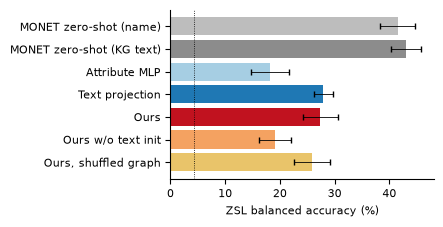

In [12]:
ms_ = [m for m in ZSL_METHODS if m in set(Z['method'])]
v = Z.groupby('method')['zsl_bacc'].agg(['mean', 'std']).reindex(ms_) * 100
fig, ax = plt.subplots(figsize=(3.4, 2.2))
ax.barh(range(len(v)), v['mean'], xerr=v['std'].fillna(0), color=[PAL[m] for m in ms_],
        error_kw=dict(lw=0.6, capsize=2))
ax.set_yticks(range(len(v)), [NAMES[m] for m in ms_]); ax.invert_yaxis()
ax.axvline(100 / np.mean([len(s['unseen']) for s in SPLITS]), ls=':', c='k', lw=0.6)
ax.set_xlabel('ZSL balanced accuracy (%)')
savefig(fig, 'fig1_zsl_bacc'); plt.show()

### Fig. 2 Seen-unseen trade-off (GZSL, split 0)

saved figures_v2\fig2_gzsl_curve.pdf


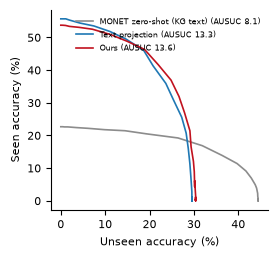

In [13]:
fig, ax = plt.subplots(figsize=(2.8, 2.6))
for m in [x for x in ('zs_full', 'text', 'kg') if x in set(Z['method'])]:
    r = Z[(Z['method'] == m) & (Z['split'] == 0)].iloc[0]
    c = np.array(sorted(set(map(tuple, r['curve'])), key=lambda t: t[1])) * 100
    ax.plot(c[:, 1], c[:, 0], c=PAL[m], lw=1.2, label=f"{NAMES[m]} (AUSUC {r['ausuc'] * 100:.1f})")
ax.set_xlabel('Unseen accuracy (%)'); ax.set_ylabel('Seen accuracy (%)')
ax.legend(fontsize=6, frameon=False)
savefig(fig, 'fig2_gzsl_curve'); plt.show()

### Fig. 3 Long-tail accuracy by frequency bin

saved figures_v2\fig3_longtail_bins.pdf


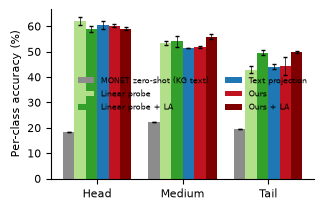

In [14]:
ms_ = [m for m in LT_METHODS if m in set(LTR['method'])]
bins = ['head', 'medium', 'tail']; w = 0.8 / len(ms_)
fig, ax = plt.subplots(figsize=(3.4, 2.2))
for i, m in enumerate(ms_):
    g = LTR[LTR['method'] == m]
    ax.bar(np.arange(3) + (i - (len(ms_) - 1) / 2) * w, g[bins].mean() * 100, w,
           yerr=g[bins].std().fillna(0) * 100, color=PAL[m], label=NAMES[m], error_kw=dict(lw=0.5, capsize=1.5))
ax.set_xticks(range(3), ['Head', 'Medium', 'Tail']); ax.set_ylabel('Per-class accuracy (%)')
ax.legend(fontsize=6, frameon=False, ncol=2)
savefig(fig, 'fig3_longtail_bins'); plt.show()

### Fig. 4 Relation-group ablation (change in ZSL BAcc vs. full graph)

saved figures_v2\fig4_ablation.pdf


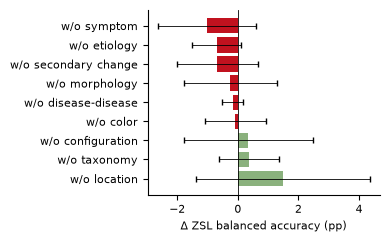

In [15]:
if ABLATION:
    full = Z[Z['method'] == 'kg'].set_index('split')['zsl_bacc']
    rows = []
    for g in GROUPS:
        a = Z[Z['method'] == 'abl:' + g].set_index('split')['zsl_bacc']
        d = (a - full.reindex(a.index)) * 100                # paired by split
        rows.append((g, d.mean(), d.std()))
    rows.sort(key=lambda t: t[1])
    fig, ax = plt.subplots(figsize=(3.0, 2.4))
    ax.barh(range(len(rows)), [r[1] for r in rows], xerr=[0 if np.isnan(r[2]) else r[2] for r in rows],
            color=['#c1121f' if r[1] < 0 else '#8ab17d' for r in rows], error_kw=dict(lw=0.6, capsize=2))
    ax.set_yticks(range(len(rows)), [f'w/o {r[0]}' for r in rows]); ax.invert_yaxis()
    ax.axvline(0, c='k', lw=0.6); ax.set_xlabel('$\\Delta$ ZSL balanced accuracy (pp)')
    savefig(fig, 'fig4_ablation'); plt.show()

### Fig. 5 Per-class accuracy on unseen diseases: zero-shot vs. ours (all splits)

improved 22% | equal 1% | worse 77%
saved figures_v2\fig5_unseen_per_class.pdf


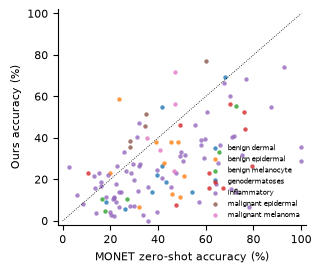

In [16]:
if {'zs_full', 'kg'} <= set(Z['method']):
    pts = []
    for k in range(N_SPLITS):
        a = Z[(Z['method'] == 'zs_full') & (Z['split'] == k)]['per_class_unseen']
        b = Z[(Z['method'] == 'kg') & (Z['split'] == k)]['per_class_unseen']
        if len(a) and len(b):
            a, b = a.iloc[0], b.iloc[0]
            pts += [(a[c], b[c], cat_of[int(c)]) for c in a if c in b]
    P = pd.DataFrame(pts, columns=['zs', 'kg', 'cat'])
    fig, ax = plt.subplots(figsize=(3.2, 2.8))
    cmap = plt.get_cmap('tab10')
    for i, (c, g) in enumerate(P.groupby('cat')):
        ax.scatter(g['zs'] * 100, g['kg'] * 100, s=10, color=cmap(i), label=c, alpha=0.8, lw=0)
    ax.plot([0, 100], [0, 100], c='k', lw=0.6, ls=':')
    ax.set_xlabel('MONET zero-shot accuracy (%)'); ax.set_ylabel(f'{OURS} accuracy (%)')
    ax.set_xlim(-2, 102); ax.set_ylim(-2, 102)
    ax.legend(fontsize=5, frameon=False, loc='lower right')
    print(f"improved {(P.kg > P.zs).mean():.0%} | equal {(P.kg == P.zs).mean():.0%} | worse {(P.kg < P.zs).mean():.0%}")
    savefig(fig, 'fig5_unseen_per_class'); plt.show()

### Fig. 6 Generated classifier weights (t-SNE, split 0)

saved figures_v2\fig6_weights_tsne.pdf


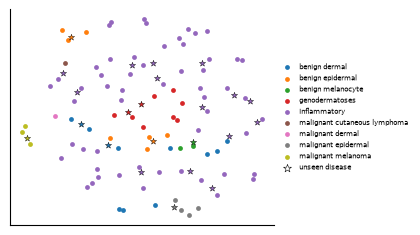

In [17]:
sp0 = SPLITS[0]
kg0 = Net('kg', ADJ).to(DEVICE); kg0.load_state_dict(torch.load(RES / 'models' / 'zsl_kg_0.pt', map_location=DEVICE))
kg0.eval()
with torch.no_grad():
    Wk = F.normalize(kg0.class_weights(), dim=-1).cpu().numpy()
try:
    from sklearn.manifold import TSNE
    E = TSNE(2, perplexity=min(15, Cn // 4), init='pca', random_state=0).fit_transform(Wk)
except Exception:
    E = (Wk - Wk.mean(0)) @ np.linalg.svd(Wk - Wk.mean(0), full_matrices=False)[2][:2].T
fig, ax = plt.subplots(figsize=(3.4, 2.8))
cmap = plt.get_cmap('tab10'); un = np.isin(np.arange(Cn), sp0['unseen'])
for i, c in enumerate(sorted(set(cat_of))):
    m = cat_of == c
    ax.scatter(E[m & ~un, 0], E[m & ~un, 1], s=12, color=cmap(i), label=c, lw=0)
    ax.scatter(E[m & un, 0], E[m & un, 1], s=22, color=cmap(i), marker='*', edgecolor='k', lw=0.3)
ax.set_xticks([]); ax.set_yticks([])
ax.scatter([], [], marker='*', c='w', edgecolor='k', lw=0.4, label='unseen disease')
ax.legend(fontsize=5, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
savefig(fig, 'fig6_weights_tsne'); plt.show()

### Fig. 7 Long-tail balanced accuracy by Fitzpatrick skin type

saved figures_v2\fig7_skin_type.pdf


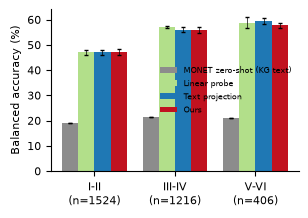

In [18]:
groups = ['I-II', 'III-IV', 'V-VI']
ms_ = [m for m in ('zs_full', 'lp', 'text', 'kg') if m in set(LTR['method'])]
w = 0.8 / len(ms_)
fig, ax = plt.subplots(figsize=(3.2, 2.1))
for i, m in enumerate(ms_):
    g = LTR[LTR['method'] == m][[f'skin_{s}' for s in groups]]
    ax.bar(np.arange(3) + (i - (len(ms_) - 1) / 2) * w, g.mean() * 100, w, yerr=g.std().fillna(0) * 100,
           color=PAL[m], label=NAMES[m], error_kw=dict(lw=0.5, capsize=1.5))
n = meta.loc[LT['te'], 'skin_group'].value_counts()
ax.set_xticks(range(3), [f'{s}\n(n={n.get(s, 0)})' for s in groups])
ax.set_ylabel('Balanced accuracy (%)'); ax.legend(fontsize=6, frameon=False)
savefig(fig, 'fig7_skin_type'); plt.show()

### Fig. 8+ Case studies on unseen diseases

Unseen-test images that the model gets right with high confidence while MONET zero-shot gets wrong. Attribute evidence is counterfactual: each attribute edge of the predicted disease is removed in turn and the drop in that disease's logit is measured, so the bars show what the graph actually contributed to this prediction. One figure per case.

In [19]:
S_kg = scores(kg0, sp0['te_u']); S_zs = scores('full', sp0['te_u']) if SAME_SPACE else None
u = sp0['unseen']; yu = y[sp0['te_u']]
P_kg = torch.softmax(torch.tensor(S_kg[:, u]), 1).numpy()
pred_kg = u[P_kg.argmax(1)]
ok = pred_kg == yu
if S_zs is not None:
    ok &= u[S_zs[:, u].argmax(1)] != yu
cand = np.where(ok)[0]
cand = cand[np.argsort(-P_kg[cand].max(1))]
picked, used = [], set()
for i in cand:                      # one case per disease
    if yu[i] not in used:
        picked.append(i); used.add(yu[i])
    if len(picked) == N_CASES:
        break

dname = tax['disease'].to_numpy()
attr_edges = edges[edges['relation'].isin(ATTR_RELS)]

@torch.no_grad()
def attribute_evidence(img_i, d):
    x = Xt[sp0['te_u'][img_i]][None]
    base = kg0(x)[0, d].item()
    rows = attr_edges[attr_edges['head'] == 'Disease:' + dname[d]]
    out = []
    for idx, r in rows.iterrows():
        adj = build_adj(edges.drop(index=idx))
        out.append((r['tail'].split(':', 1)[1], r['relation'], base - kg0(x, adj)[0, d].item()))
    return sorted(out, key=lambda t: -t[2])

saved figures_v2\fig8_case1.pdf


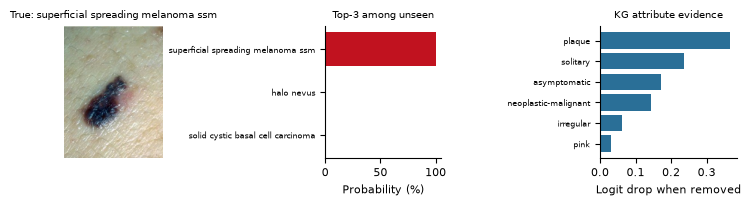

In [20]:
# case 1
if len(picked) > 0:
    i = picked[0]; d = yu[i]
    ev = attribute_evidence(i, d)[:6]
    top = np.argsort(-P_kg[i])[:3]
    fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.1), gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    ax[0].imshow(Image.open(img_path[sp0['te_u'][i]]).convert('RGB')); ax[0].axis('off')
    ax[0].set_title(f'True: {dname[d]}', fontsize=7)
    ax[1].barh(range(3), P_kg[i][top] * 100, color=['#c1121f' if u[t] == d else '#bdbdbd' for t in top])
    ax[1].set_yticks(range(3), [dname[u[t]] for t in top], fontsize=6); ax[1].invert_yaxis()
    ax[1].set_xlabel('Probability (%)'); ax[1].set_title('Top-3 among unseen', fontsize=7)
    ax[2].barh(range(len(ev)), [e[2] for e in ev], color='#2a6f97')
    ax[2].set_yticks(range(len(ev)), [e[0] for e in ev], fontsize=6); ax[2].invert_yaxis()
    ax[2].set_xlabel('Logit drop when removed'); ax[2].set_title('KG attribute evidence', fontsize=7)
    plt.tight_layout()
    savefig(fig, 'fig8_case1'); plt.show()

saved figures_v2\fig8_case2.pdf


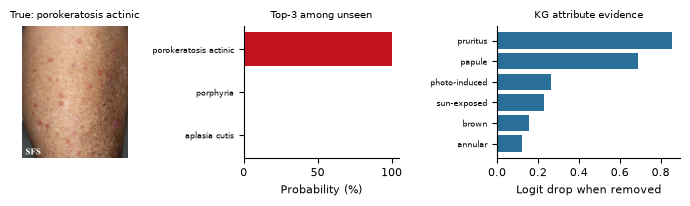

In [21]:
# case 2
if len(picked) > 1:
    i = picked[1]; d = yu[i]
    ev = attribute_evidence(i, d)[:6]
    top = np.argsort(-P_kg[i])[:3]
    fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.1), gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    ax[0].imshow(Image.open(img_path[sp0['te_u'][i]]).convert('RGB')); ax[0].axis('off')
    ax[0].set_title(f'True: {dname[d]}', fontsize=7)
    ax[1].barh(range(3), P_kg[i][top] * 100, color=['#c1121f' if u[t] == d else '#bdbdbd' for t in top])
    ax[1].set_yticks(range(3), [dname[u[t]] for t in top], fontsize=6); ax[1].invert_yaxis()
    ax[1].set_xlabel('Probability (%)'); ax[1].set_title('Top-3 among unseen', fontsize=7)
    ax[2].barh(range(len(ev)), [e[2] for e in ev], color='#2a6f97')
    ax[2].set_yticks(range(len(ev)), [e[0] for e in ev], fontsize=6); ax[2].invert_yaxis()
    ax[2].set_xlabel('Logit drop when removed'); ax[2].set_title('KG attribute evidence', fontsize=7)
    plt.tight_layout()
    savefig(fig, 'fig8_case2'); plt.show()

saved figures_v2\fig8_case3.pdf


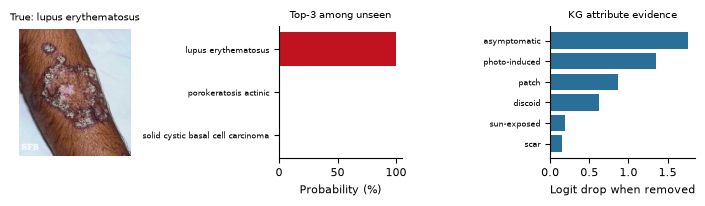

In [22]:
# case 3
if len(picked) > 2:
    i = picked[2]; d = yu[i]
    ev = attribute_evidence(i, d)[:6]
    top = np.argsort(-P_kg[i])[:3]
    fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.1), gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    ax[0].imshow(Image.open(img_path[sp0['te_u'][i]]).convert('RGB')); ax[0].axis('off')
    ax[0].set_title(f'True: {dname[d]}', fontsize=7)
    ax[1].barh(range(3), P_kg[i][top] * 100, color=['#c1121f' if u[t] == d else '#bdbdbd' for t in top])
    ax[1].set_yticks(range(3), [dname[u[t]] for t in top], fontsize=6); ax[1].invert_yaxis()
    ax[1].set_xlabel('Probability (%)'); ax[1].set_title('Top-3 among unseen', fontsize=7)
    ax[2].barh(range(len(ev)), [e[2] for e in ev], color='#2a6f97')
    ax[2].set_yticks(range(len(ev)), [e[0] for e in ev], fontsize=6); ax[2].invert_yaxis()
    ax[2].set_xlabel('Logit drop when removed'); ax[2].set_title('KG attribute evidence', fontsize=7)
    plt.tight_layout()
    savefig(fig, 'fig8_case3'); plt.show()